# Milestone 3 — Hyperparameter sweep and detection gallery
**IE 7615 · Group 1 · Dario Garza**

This notebook completes Dario's two assigned tasks:

1. Compare **confidence** and **NMS IoU** thresholds using the team's fixed YOLOv8 checkpoint.
2. Produce **at least ten annotated multi-face test examples**, with confidence scores and explanatory captions.

The sweep uses validation to select settings. Only the baseline and selected settings are evaluated on test.
Class-aware and class-agnostic NMS are compared as an extra control for overlapping identity predictions.

**Required:** the updated project ZIP and Aditi's trained `best.pt`, or `milestone03_training_results.zip`.
The project ZIP has the data but does not include those trained YOLO weights. Milestone 1 classification weights cannot replace them.

Run cells in order. In Colab, choose a GPU under **Runtime → Change runtime type** if one is available; CPU also works.


## 1. Locate the project

If you opened this notebook directly in Colab, this cell asks you to upload the updated project ZIP.
If the project is already extracted locally or in Colab, it is reused. No dataset regeneration is needed.


In [1]:
import importlib.util
import json
import os
import sys
import zipfile
from datetime import datetime, timezone
from pathlib import Path

IN_COLAB = (importlib.util.find_spec("google") is not None and
            importlib.util.find_spec("google.colab") is not None)

def find_project():
    candidates = [Path.cwd(), Path.cwd().parent]
    for parent in [Path.cwd(), Path("/content")]:
        if parent.is_dir():
            candidates.extend(path for path in parent.iterdir() if path.is_dir())
    for candidate in candidates:
        if (candidate / "project_milestone03/hyperparameter_sweep.py").is_file() and (candidate / "project_milestone02/dataset/data.yaml").is_file():
            return candidate.resolve()
    return None

project_dir = find_project()
if project_dir is None:
    if not IN_COLAB:
        raise FileNotFoundError("Extract the updated project ZIP and open this notebook from its project_milestone03 folder.")
    from google.colab import files
    print("Upload the updated IE7615 project ZIP containing hyperparameter_sweep.py and the dataset.")
    uploaded_project = files.upload()
    project_archives = [Path(name) for name in uploaded_project if name.lower().endswith(".zip")]
    if len(project_archives) != 1:
        raise ValueError("Upload exactly one updated project ZIP.")
    destination = Path.cwd().resolve()
    with zipfile.ZipFile(project_archives[0]) as archive:
        for member in archive.infolist():
            if not (destination / member.filename).resolve().is_relative_to(destination):
                raise ValueError("The ZIP contains an unsafe extraction path.")
        archive.extractall(destination)
    project_dir = find_project()
    if project_dir is None:
        raise FileNotFoundError("The ZIP does not contain the updated hyperparameter script and Milestone 2 dataset.")

print("Project:", project_dir)


Project: C:\Users\Yose\IE7615-Group1-Project1


## 2. Install the sweep dependencies

Use the same Ultralytics release as the team's existing baseline evaluation. Keep Colab's installed PyTorch/CUDA environment.


In [2]:
import subprocess

subprocess.run([
    sys.executable, "-m", "pip", "install", "-q", "-r",
    str(project_dir / "project_milestone03/requirements_hyperparameters.txt"),
], check=True)

import pandas as pd
import torch
import ultralytics
from IPython.display import Image, Markdown, display

sys.path.insert(0, str(project_dir / "project_milestone03"))
from hyperparameter_sweep import audit_dataset, resolve_checkpoint, run_experiment, sha256

print("Ultralytics:", ultralytics.__version__)
print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())


Ultralytics: 8.4.174
PyTorch: 2.14.0+cpu
CUDA available: False


## 3. Supply Aditi's checkpoint

Choose **one** input: `best.pt` or the training-results ZIP containing `best.pt`.
This cell automatically requests an upload in Colab if the file is not already present.

For local execution, set `checkpoint_input` below to your file path.


In [3]:
checkpoint_input = Path(os.environ.get(
    "M3_CHECKPOINT_INPUT", str(project_dir / "project_milestone03/weights/best.pt")
)).expanduser()

if not checkpoint_input.is_file():
    if not IN_COLAB:
        raise FileNotFoundError("Set checkpoint_input to Aditi's best.pt or milestone03_training_results.zip.")
    from google.colab import files
    print("Upload Aditi's best.pt OR milestone03_training_results.zip.")
    uploaded_checkpoint = files.upload()
    checkpoint_candidates = [Path(name) for name in uploaded_checkpoint if Path(name).suffix.lower() in (".pt", ".zip")]
    if len(checkpoint_candidates) != 1:
        raise ValueError("Upload exactly one .pt checkpoint or training-results ZIP.")
    checkpoint_input = checkpoint_candidates[0].resolve()

checkpoint_path = checkpoint_input if checkpoint_input.suffix.lower() == ".pt" else None
training_zip_path = checkpoint_input if checkpoint_input.suffix.lower() == ".zip" else None
if checkpoint_path is None and training_zip_path is None:
    raise ValueError("Checkpoint input must be a .pt file or a .zip file.")
print("Checkpoint input:", checkpoint_input.name)


Checkpoint input: milestone03_training_results.zip


## 4. Verify the dataset and define the experiment

The default grid contains **4 confidence values × 3 NMS IoU values × 2 class modes = 24 configurations**.
The image size remains 640, matching the baseline. No training weights are changed.

The project data has 504 training images, 36 validation images and 36 held-out test images.
The source-photo audit checks that no photo crosses split boundaries.


In [4]:
import tempfile

dataset_dir = project_dir / "project_milestone02/dataset"
data_audit = audit_dataset(dataset_dir)
display(pd.DataFrame([
    {"split": split, "images": values["images"], "labelled_faces": values["faces"]}
    for split, values in data_audit["splits"].items()
]))
print("Shared source photos:", data_audit["shared_source_photos"])

reference = json.loads((project_dir / "project_milestone03/results/metrics.json").read_text())
with tempfile.TemporaryDirectory() as temporary:
    resolved_checkpoint = resolve_checkpoint(checkpoint_path, training_zip_path, Path(temporary))
    checkpoint_digest = sha256(resolved_checkpoint)
print("Matches Aditi's reference checkpoint:", checkpoint_digest == reference["checkpoint_sha256"])
print("Matches the baseline dataset:", data_audit["dataset_sha256"] == reference["dataset"]["dataset_sha256"])

confidence_values = [0.10, 0.25, 0.50, 0.75]
nms_iou_values = [0.30, 0.50, 0.70]
agnostic_nms_values = [False, True]
device = "0" if torch.cuda.is_available() else "cpu"
batch_size = 8
image_size = 640
run_stamp = datetime.now(timezone.utc).strftime("%Y%m%d_%H%M%S_%f")
output_dir = project_dir / "project_milestone03/results" / f"dario_sweep_{run_stamp}"
print("Device:", device)
print("Configurations:", len(confidence_values) * len(nms_iou_values) * len(agnostic_nms_values))
print("Output:", output_dir)


,split,images,labelled_faces
0,train,504,1596
1,val,36,111
2,test,36,113


Shared source photos: 0
Matches Aditi's reference checkpoint: True
Matches the baseline dataset: True
Device: cpu
Configurations: 24
Output: C:\Users\Yose\IE7615-Group1-Project1\project_milestone03\results\dario_sweep_20261010_010347_535395


## 5. Run validation, lock the settings and evaluate test

Selection maximizes **validation micro-F1**, then recall, precision, mAP@0.5:0.95,
class-aware NMS and proximity to baseline. The selected settings are saved before test evaluation.

**Reading the scores:** mAP uses the common confidence floor of 0.001.
Precision, recall and F1 use the confidence specified in each row. mAP is repeated across
confidence rows sharing the same NMS settings. NMS IoU is separate from the fixed
IoU >= 0.50 used to match a prediction to a labelled face.

Only six validation passes are needed: predictions are reused across confidence cutoffs.
The script retains those low-confidence predictions for auditing.


In [5]:
run_summary = run_experiment(
    checkpoint=checkpoint_path,
    training_zip=training_zip_path,
    dataset=dataset_dir,
    output=output_dir,
    device=device,
    batch=batch_size,
    image_size=image_size,
    confidences=confidence_values,
    nms_ious=nms_iou_values,
    agnostic_modes=agnostic_nms_values,
    gallery_count=10,
)
print("Selected using validation only:", run_summary["selection"]["config_id"])


Ultralytics 8.4.174  Python-3.13.9 torch-2.14.0+cpu CPU (Intel Core i7-7700K 4.20GHz)


Model summary (fused): 72 layers, 3,006,623 parameters, 0 gradients, 8.1 GFLOPs


val: Fast image access  (ping: 0.10.0 ms, read: 301.667.2 MB/s, size: 46.3 KB)


val: Scanning C:\Users\Yose\IE7615-Group1-Project1\project_milestone02\dataset\val\labels.cache... 36 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 36/36 6.6Mit/s 0.0s

                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 20% ━━────────── 1/5 1.2s/it 0.4s<4.9s

...

                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 5/5 3.1it/s 1.6s

                   all         36        113      0.913      0.942      0.962      0.862


Speed: 1.3ms preprocess, 33.4ms inference, 0.0ms loss, 0.5ms postprocess per image


Finished. Selected on validation: conf_0.50_iou_0.70_aware. Outputs: C:\Users\Yose\IE7615-Group1-Project1\project_milestone03\results\dario_sweep_20261010_010347_535395


Selected using validation only: conf_0.50_iou_0.70_aware


## 6. Inspect the comparison and per-identity results

Precision and recall below are **fixed-threshold** scores. Mean matched IoU describes correct
same-identity detections only; missed faces and false positives are counted separately.


,config_id,map50,map50_95,precision,recall,f1,mean_matched_iou,fp,fn
0,conf_0.10_iou_0.30_aware,0.9721,0.8692,0.8211,0.9099,0.8632,0.9319,22,10
1,conf_0.10_iou_0.30_agnostic,0.8759,0.7824,0.8829,0.8829,0.8829,0.9314,13,13
2,conf_0.10_iou_0.50_aware,0.9721,0.8692,0.8211,0.9099,0.8632,0.9319,22,10
3,conf_0.10_iou_0.50_agnostic,0.8759,0.7824,0.8829,0.8829,0.8829,0.9314,13,13
4,conf_0.10_iou_0.70_aware,0.9721,0.8692,0.8145,0.9099,0.8596,0.9319,23,10
5,conf_0.10_iou_0.70_agnostic,0.8759,0.7824,0.8596,0.8829,0.8711,0.9314,16,13
6,conf_0.25_iou_0.30_aware,0.9721,0.8692,0.8609,0.8919,0.8761,0.9313,16,12
7,conf_0.25_iou_0.30_agnostic,0.8759,0.7824,0.8829,0.8829,0.8829,0.9314,13,13
8,conf_0.25_iou_0.50_aware,0.9721,0.8692,0.8609,0.8919,0.8761,0.9313,16,12
9,conf_0.25_iou_0.50_agnostic,0.8759,0.7824,0.8829,0.8829,0.8829,0.9314,13,13


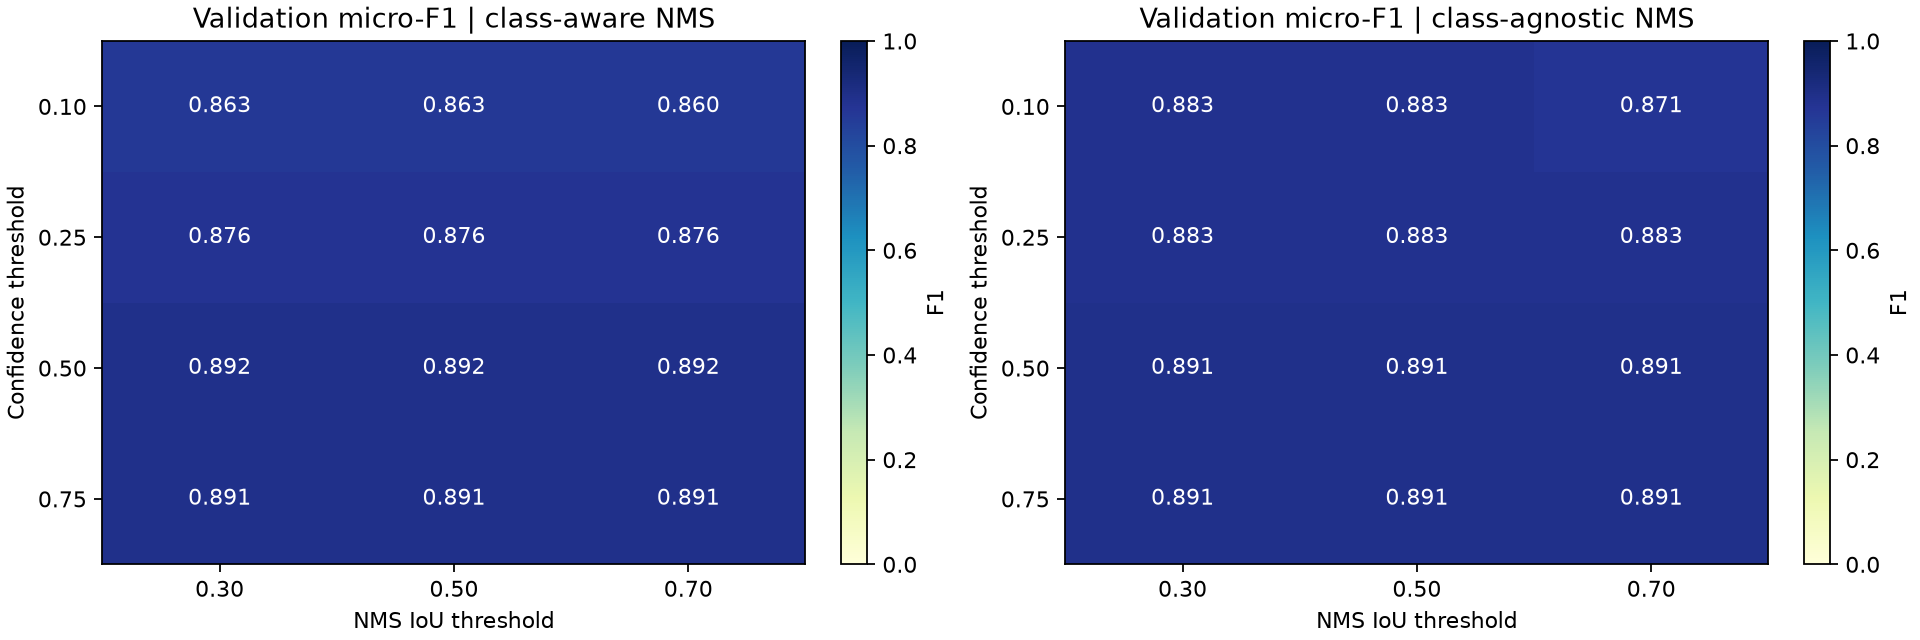

Held-out test: predeclared baseline and selected configuration


,config_id,map50,map50_95,precision,recall,f1,mean_matched_iou,fp,fn
0,conf_0.25_iou_0.70_aware,0.9623,0.8623,0.8983,0.9381,0.9177,0.9314,12,7
1,conf_0.50_iou_0.70_aware,0.9623,0.8623,0.9286,0.9204,0.9244,0.9325,8,9


Per-identity held-out test scores


,split,config_id,identity,tp,fp,fn,precision,recall,f1,mean_matched_iou,map50,map50_95
120,test,conf_0.25_iou_0.70_aware,7007,17,0,7,1.0000,0.7083,0.8293,0.9151,0.9310,0.8164
121,test,conf_0.25_iou_0.70_aware,2970,23,3,0,0.8846,1.0000,0.9388,0.9371,0.9950,0.8913
122,test,conf_0.25_iou_0.70_aware,2336,24,0,0,1.0000,1.0000,1.0000,0.9333,0.9950,0.8991
123,test,conf_0.25_iou_0.70_aware,7,23,6,0,0.7931,1.0000,0.8846,0.9321,0.9004,0.8032
124,test,conf_0.25_iou_0.70_aware,4428,19,3,0,0.8636,1.0000,0.9268,0.9356,0.9902,0.9017
125,test,conf_0.50_iou_0.70_aware,7007,15,0,9,1.0000,0.6250,0.7692,0.9208,0.9310,0.8164
126,test,conf_0.50_iou_0.70_aware,2970,23,0,0,1.0000,1.0000,1.0000,0.9371,0.9950,0.8913
127,test,conf_0.50_iou_0.70_aware,2336,24,0,0,1.0000,1.0000,1.0000,0.9333,0.9950,0.8991
128,test,conf_0.50_iou_0.70_aware,7,23,5,0,0.8214,1.0000,0.9020,0.9321,0.9004,0.8032
129,test,conf_0.50_iou_0.70_aware,4428,19,3,0,0.8636,1.0000,0.9268,0.9356,0.9902,0.9017


In [6]:
validation_table = pd.read_csv(output_dir / "validation_sweep.csv")
score_columns = ["config_id", "map50", "map50_95", "precision", "recall", "f1", "mean_matched_iou", "fp", "fn"]
display(validation_table[score_columns].round(4))
display(Image(filename=str(output_dir / "validation_f1_heatmap.png"), width=1100))
print("Held-out test: predeclared baseline and selected configuration")
display(pd.read_csv(output_dir / "test_metrics.csv")[score_columns].round(4))
print("Per-identity held-out test scores")
per_class_table = pd.read_csv(output_dir / "per_class_metrics.csv", dtype={"identity": str})
display(per_class_table.loc[per_class_table["split"] == "test"].round(4))


## 7. Detection visualization gallery

Each image has a ground-truth panel and a prediction panel. Predicted boxes include identity IDs
and confidence scores. Green predictions match the correct identity at IoU >= 0.50;
red predictions are unmatched. Captions explain misses, wrong identities and overlapping predictions.

The gallery prioritizes actual failures and clear successes. Baseline failures can supplement
selected-configuration failures, with the source settings clearly marked. These images do not influence selection.


**Failure — test_0002.jpg**  
Settings: `conf_0.50_iou_0.70_aware` (selected configuration).

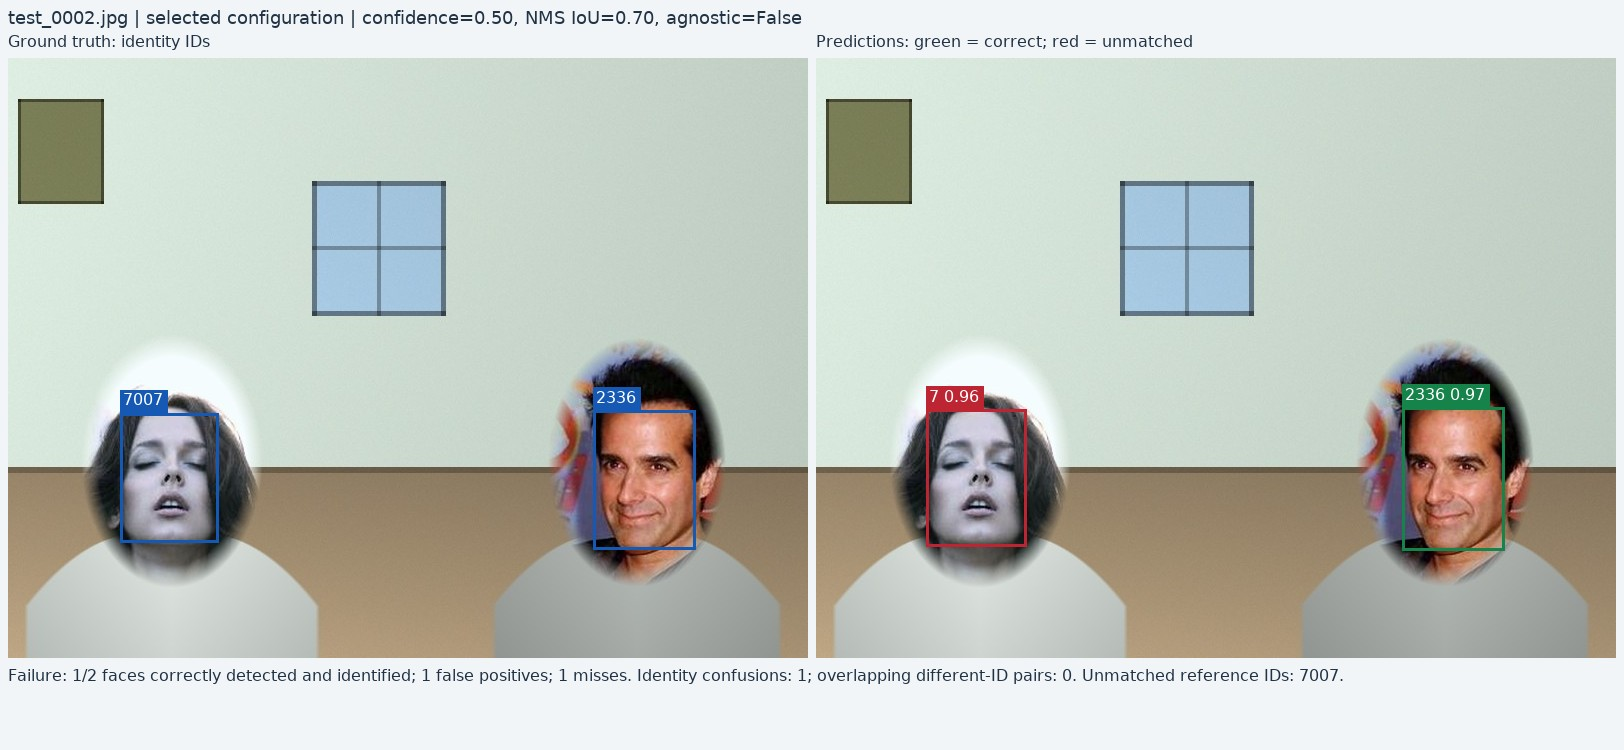

Failure: 1/2 faces correctly detected and identified; 1 false positives; 1 misses. Identity confusions: 1; overlapping different-ID pairs: 0. Unmatched reference IDs: 7007.

**Failure — test_0004.jpg**  
Settings: `conf_0.50_iou_0.70_aware` (selected configuration).

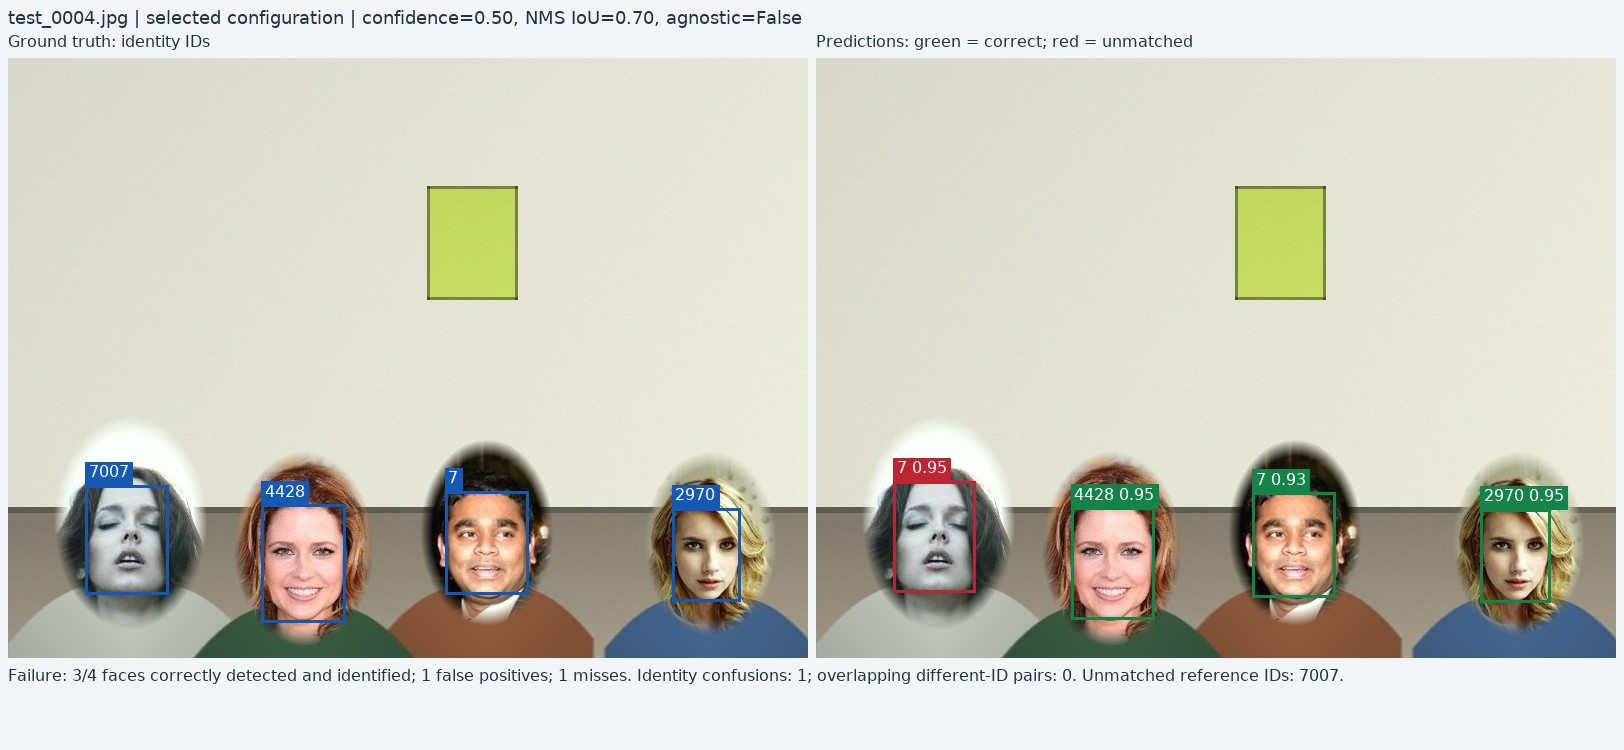

Failure: 3/4 faces correctly detected and identified; 1 false positives; 1 misses. Identity confusions: 1; overlapping different-ID pairs: 0. Unmatched reference IDs: 7007.

**Failure — test_0009.jpg**  
Settings: `conf_0.50_iou_0.70_aware` (selected configuration).

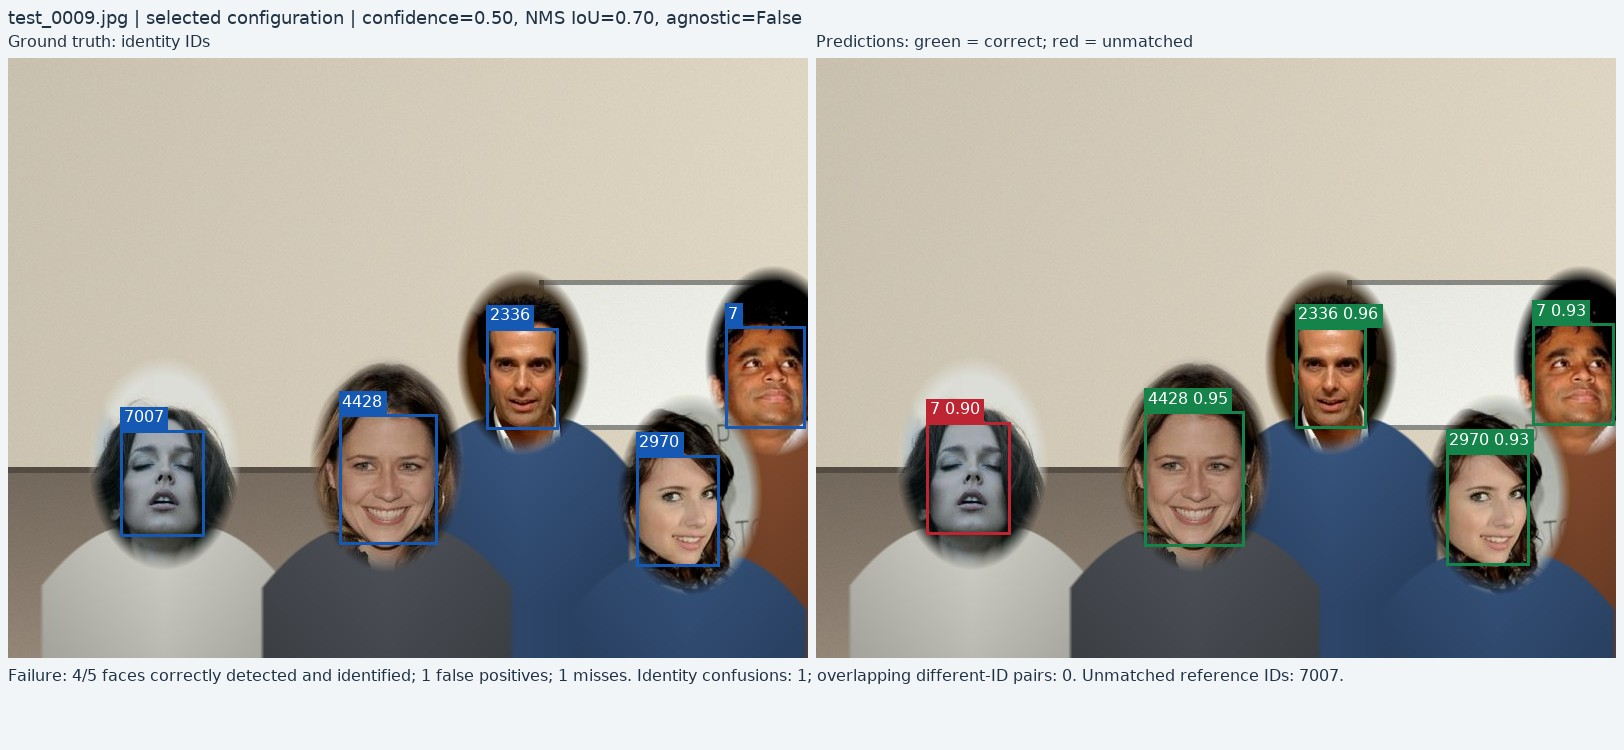

Failure: 4/5 faces correctly detected and identified; 1 false positives; 1 misses. Identity confusions: 1; overlapping different-ID pairs: 0. Unmatched reference IDs: 7007.

**Failure — test_0012.jpg**  
Settings: `conf_0.50_iou_0.70_aware` (selected configuration).

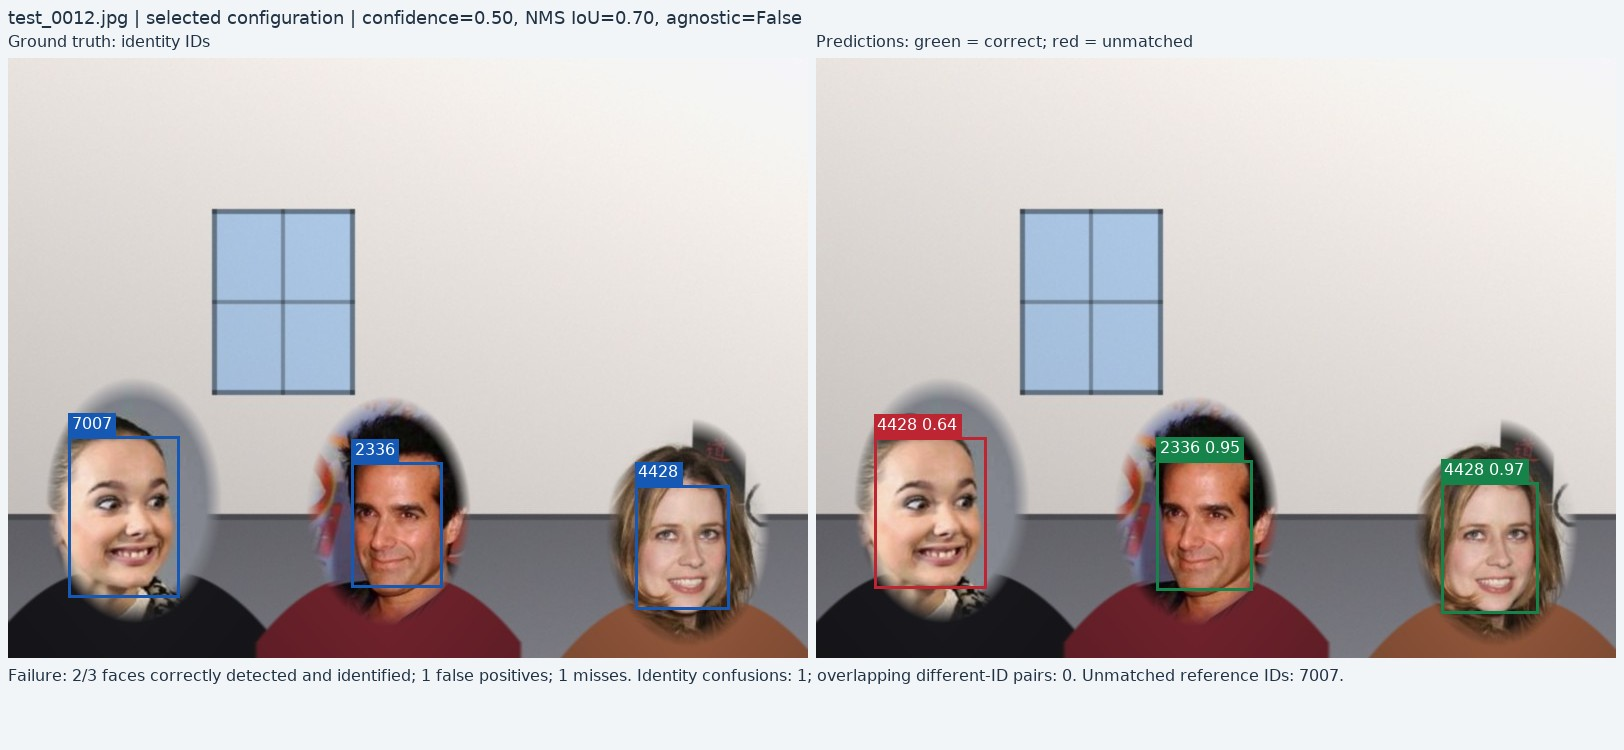

Failure: 2/3 faces correctly detected and identified; 1 false positives; 1 misses. Identity confusions: 1; overlapping different-ID pairs: 0. Unmatched reference IDs: 7007.

**Failure — test_0020.jpg**  
Settings: `conf_0.50_iou_0.70_aware` (selected configuration).

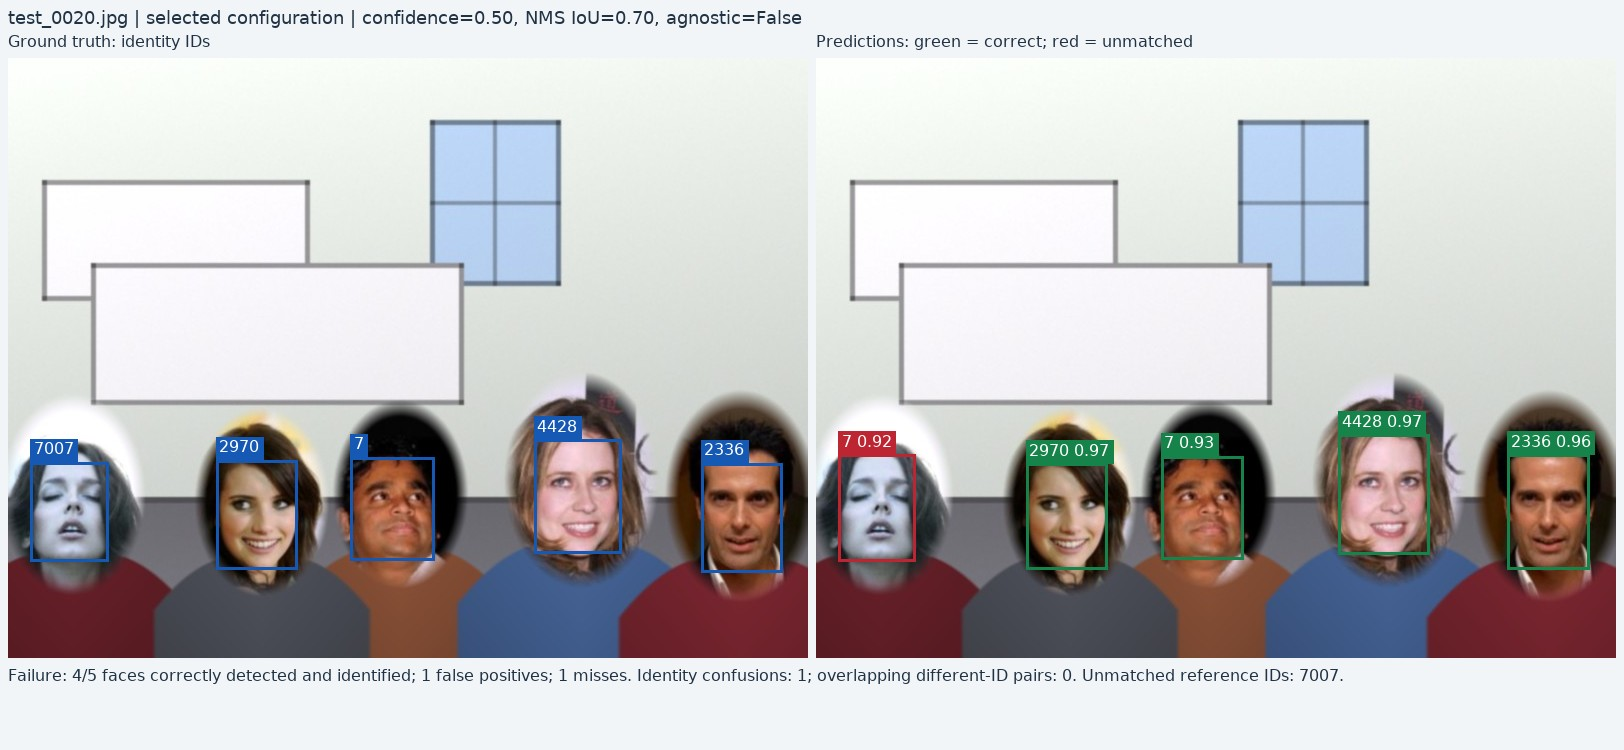

Failure: 4/5 faces correctly detected and identified; 1 false positives; 1 misses. Identity confusions: 1; overlapping different-ID pairs: 0. Unmatched reference IDs: 7007.

**Success — test_0005.jpg**  
Settings: `conf_0.50_iou_0.70_aware` (selected configuration).

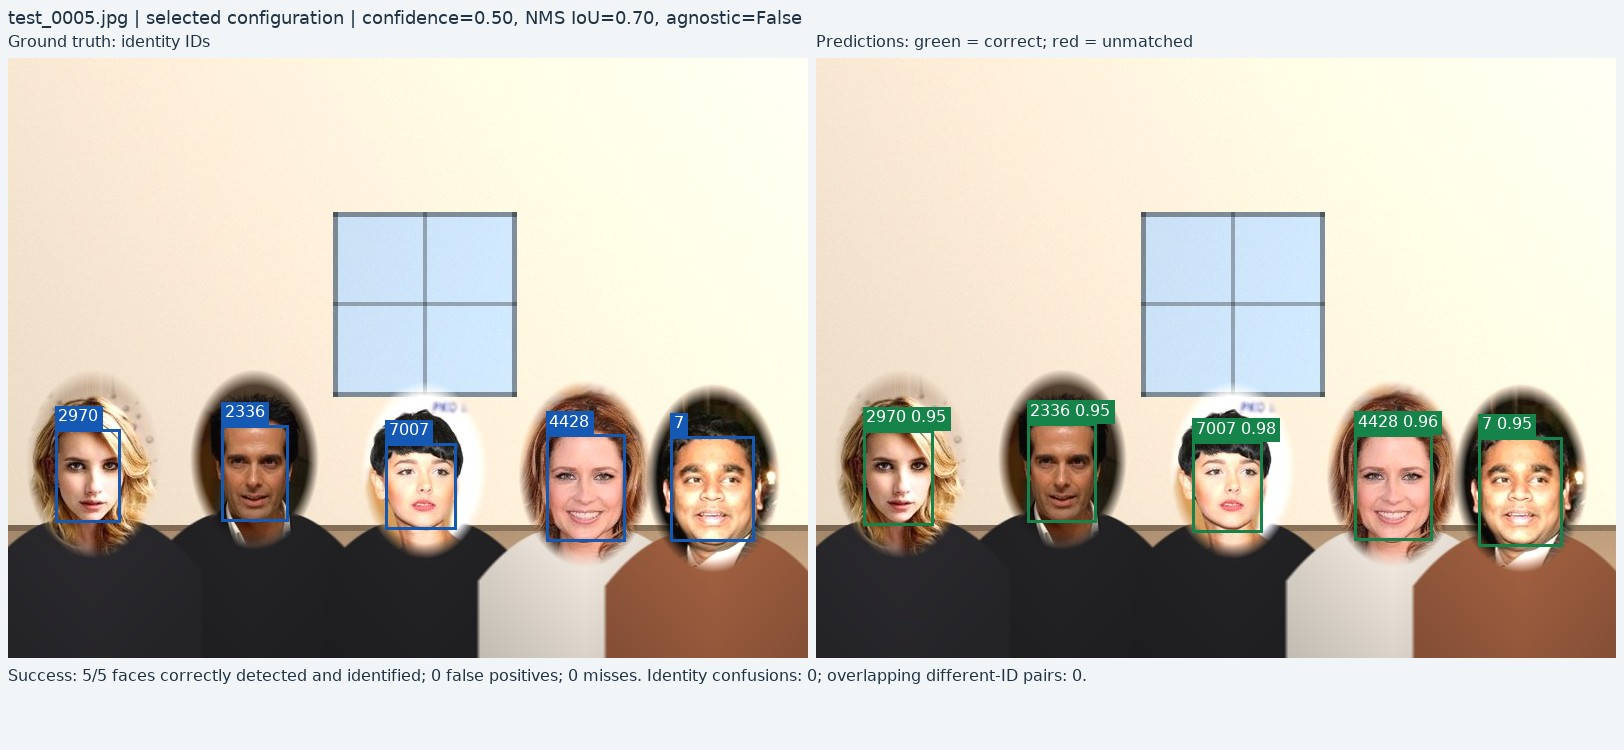

Success: 5/5 faces correctly detected and identified; 0 false positives; 0 misses. Identity confusions: 0; overlapping different-ID pairs: 0.

**Success — test_0008.jpg**  
Settings: `conf_0.50_iou_0.70_aware` (selected configuration).

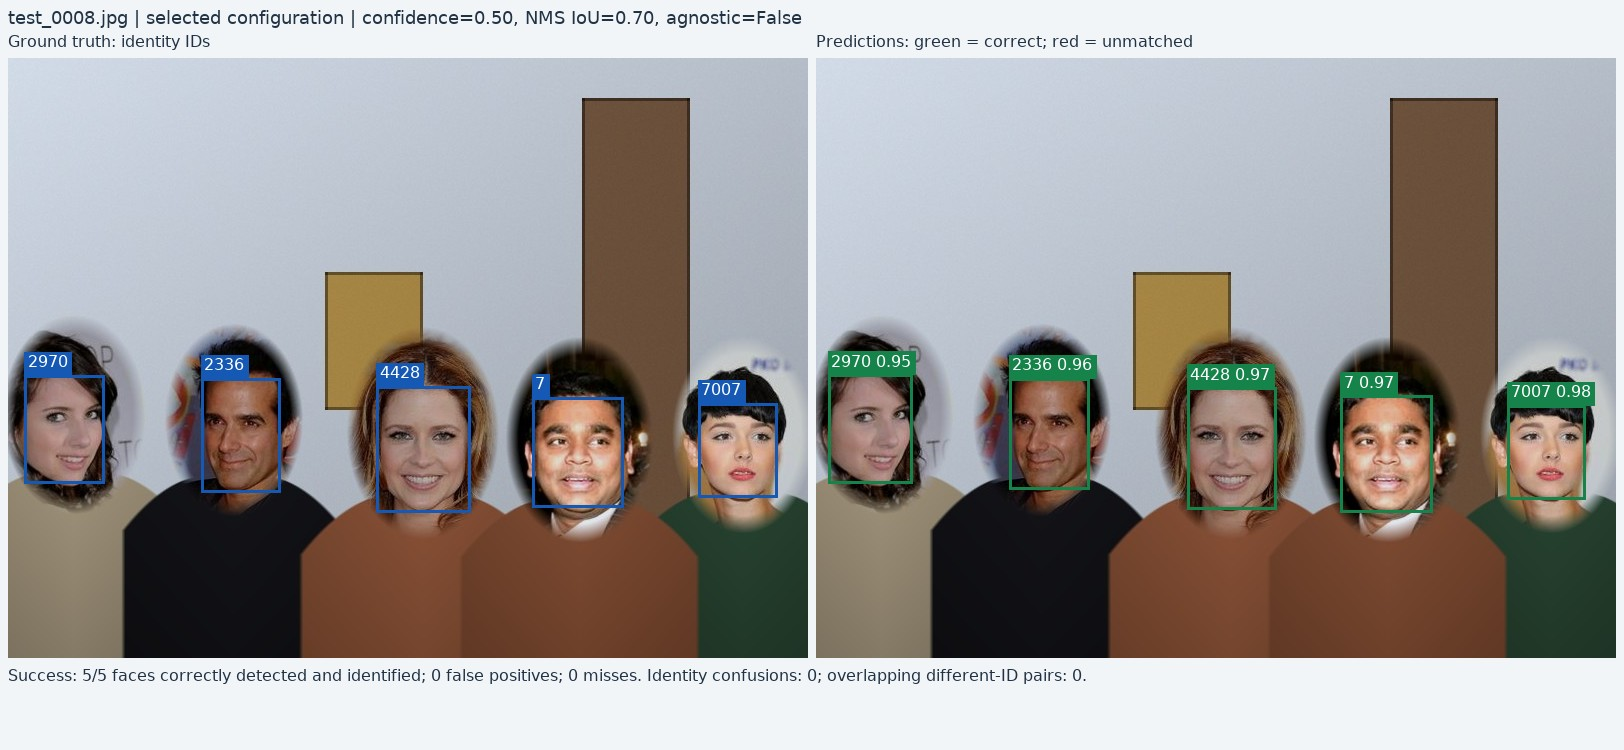

Success: 5/5 faces correctly detected and identified; 0 false positives; 0 misses. Identity confusions: 0; overlapping different-ID pairs: 0.

**Success — test_0013.jpg**  
Settings: `conf_0.50_iou_0.70_aware` (selected configuration).

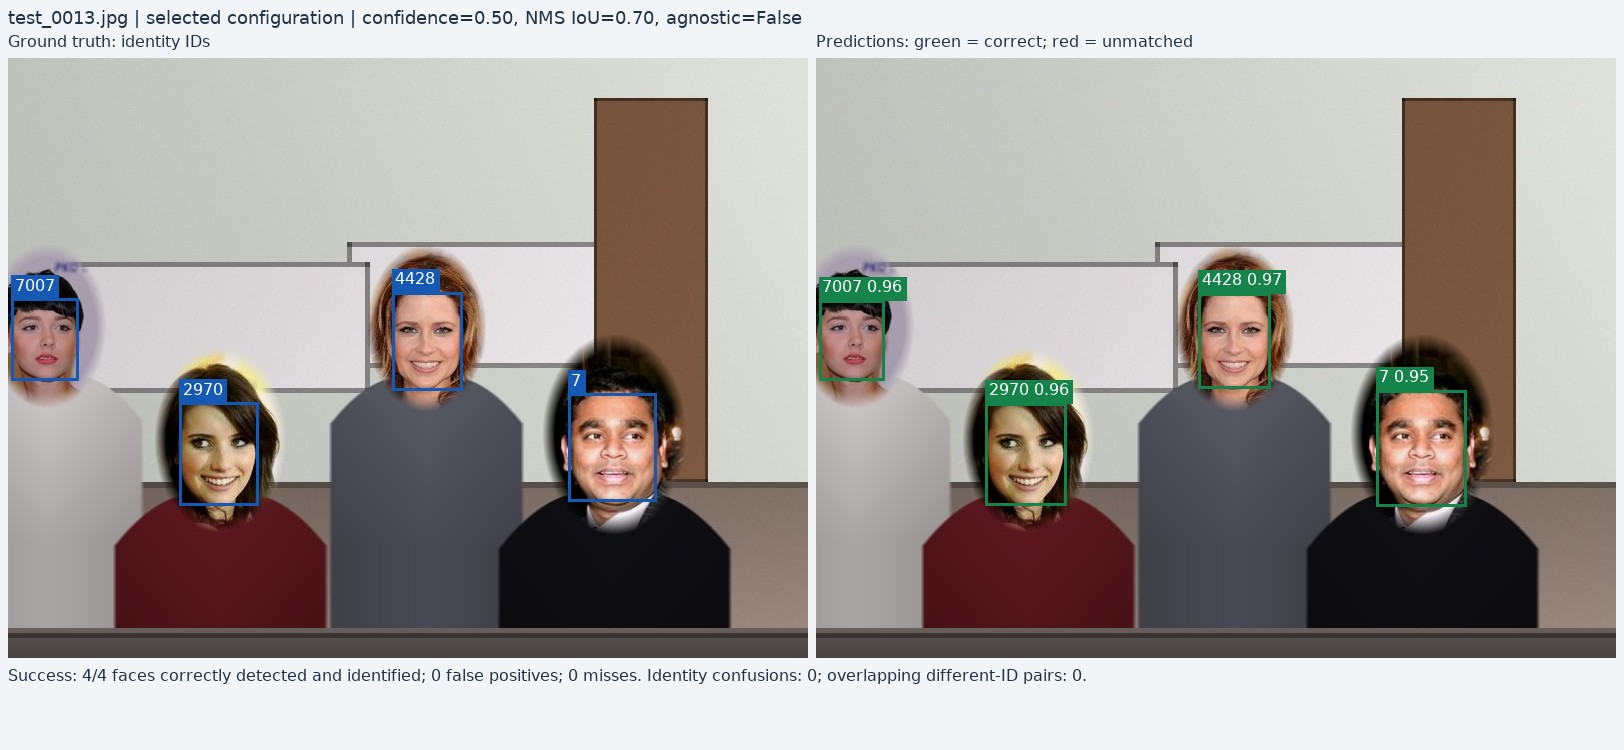

Success: 4/4 faces correctly detected and identified; 0 false positives; 0 misses. Identity confusions: 0; overlapping different-ID pairs: 0.

**Success — test_0021.jpg**  
Settings: `conf_0.50_iou_0.70_aware` (selected configuration).

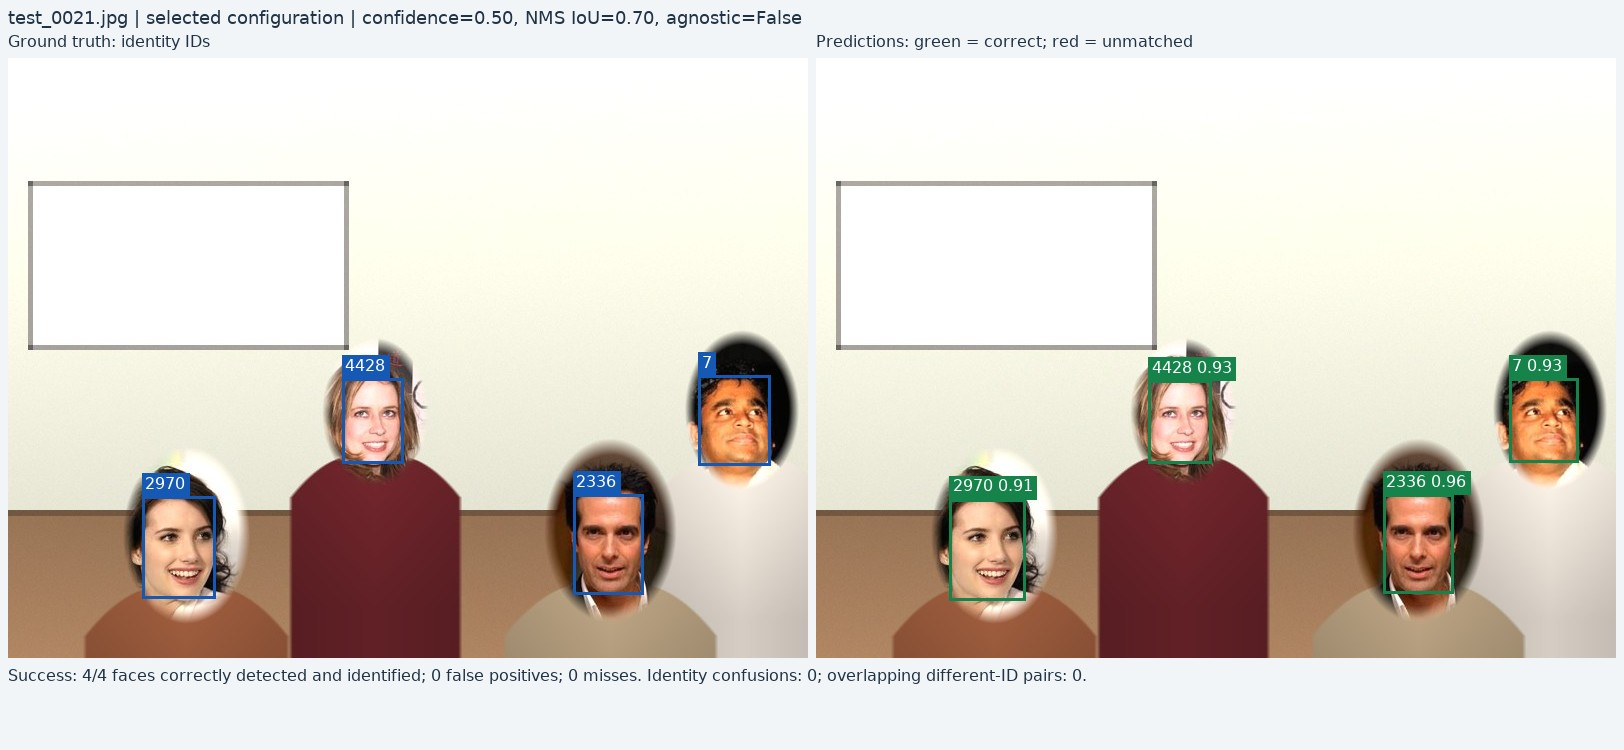

Success: 4/4 faces correctly detected and identified; 0 false positives; 0 misses. Identity confusions: 0; overlapping different-ID pairs: 0.

**Success — test_0023.jpg**  
Settings: `conf_0.50_iou_0.70_aware` (selected configuration).

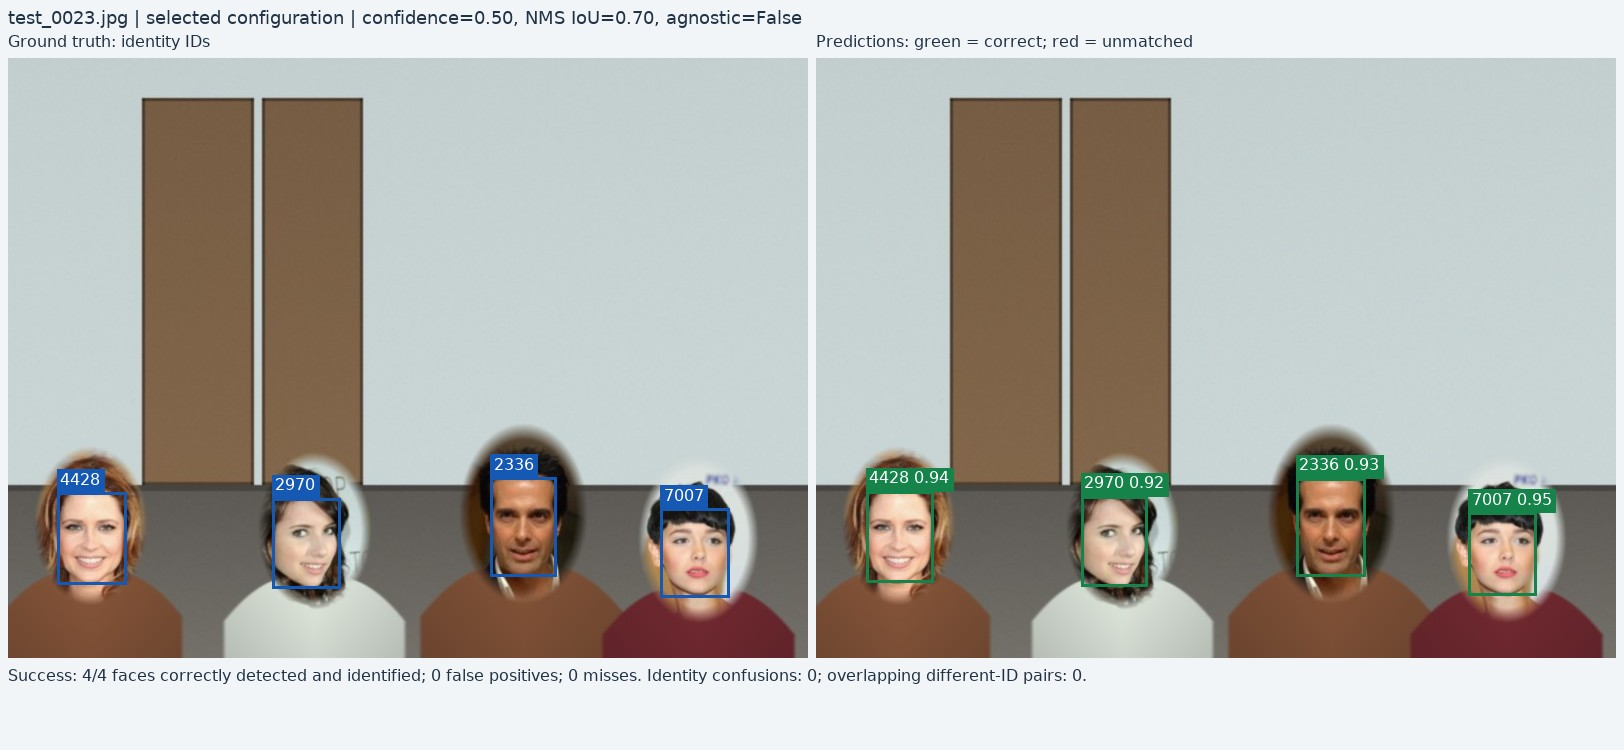

Success: 4/4 faces correctly detected and identified; 0 false positives; 0 misses. Identity confusions: 0; overlapping different-ID pairs: 0.

In [7]:
gallery_rows = pd.read_csv(output_dir / "gallery/captions.csv")
for row in gallery_rows.to_dict("records"):
    display(Markdown(f"**{row['status']} — {row['image']}**  \nSettings: `{row['config_id']}` ({row['source']})."))
    display(Image(filename=str(output_dir / "gallery" / row["panel"]), width=1100))
    display(Markdown(row["caption"]))


## 8. Summary and teammate handoff

The generated Markdown summary has the sweep table, numerical interpretation, selected settings,
test comparison and gallery links. Yosephine can use it in the team's detection-results document.
Murat can reuse `selected_config.json` and the same checkpoint in the live demo.
Aditi's existing training log remains the source for training/validation loss curves; this sweep does not retrain.


In [8]:
display(Markdown((output_dir / "hyperparameter_summary.md").read_text(encoding="utf-8")))
print("Checkpoint SHA-256:", run_summary["checkpoint_sha256"])
print("Dataset SHA-256:", run_summary["dataset"]["dataset_sha256"])
print("Recorded environment:", run_summary["environment"])


# Milestone 3 — Hyperparameter sweep

Owner: Dario Garza.

## Method

This is an **inference hyperparameter sweep**, using one fixed YOLOv8 checkpoint. It varies confidence and the IoU threshold used by NMS. Both are explicitly allowed by the milestone. Class-aware and class-agnostic NMS are compared as an additional control for overlapping identity predictions. Learning rate, training augmentation and model weights are unchanged.

There are 24 configurations. Validation contains 36 images and 111 faces. The selection rule is maximum validation micro-F1, then recall, precision, mAP@0.5:0.95, class-aware NMS and proximity to baseline. This rule is fixed before test evaluation.

mAP uses a confidence floor of 0.001 and integrates across confidence cutoffs. Precision, recall and F1 use each row's stated confidence. Consequently, mAP is shared by rows with the same NMS settings; changing the reporting threshold alone does not change that AP calculation. The NMS IoU threshold is separate from the fixed IoU >= 0.50 used to match a prediction to a reference box. Mean matched IoU includes correct same-identity matches only and excludes misses and false positives. Matching is one-to-one in descending IoU, consistent with the baseline evaluation script. Ultralytics' automatic max-F1 precision/recall are saved separately in the run metadata.

## Validation comparison

| Configuration | Split | mAP@0.5 | mAP@0.5:0.95 | Precision | Recall | F1 | Mean matched IoU | FP | FN |
|---|---|---:|---:|---:|---:|---:|---:|---:|---:|
| conf_0.10_iou_0.30_aware | val | 0.9721 | 0.8692 | 0.8211 | 0.9099 | 0.8632 | 0.9319 | 22 | 10 |
| conf_0.10_iou_0.30_agnostic | val | 0.8759 | 0.7824 | 0.8829 | 0.8829 | 0.8829 | 0.9314 | 13 | 13 |
| conf_0.10_iou_0.50_aware | val | 0.9721 | 0.8692 | 0.8211 | 0.9099 | 0.8632 | 0.9319 | 22 | 10 |
| conf_0.10_iou_0.50_agnostic | val | 0.8759 | 0.7824 | 0.8829 | 0.8829 | 0.8829 | 0.9314 | 13 | 13 |
| conf_0.10_iou_0.70_aware | val | 0.9721 | 0.8692 | 0.8145 | 0.9099 | 0.8596 | 0.9319 | 23 | 10 |
| conf_0.10_iou_0.70_agnostic | val | 0.8759 | 0.7824 | 0.8596 | 0.8829 | 0.8711 | 0.9314 | 16 | 13 |
| conf_0.25_iou_0.30_aware | val | 0.9721 | 0.8692 | 0.8609 | 0.8919 | 0.8761 | 0.9313 | 16 | 12 |
| conf_0.25_iou_0.30_agnostic | val | 0.8759 | 0.7824 | 0.8829 | 0.8829 | 0.8829 | 0.9314 | 13 | 13 |
| conf_0.25_iou_0.50_aware | val | 0.9721 | 0.8692 | 0.8609 | 0.8919 | 0.8761 | 0.9313 | 16 | 12 |
| conf_0.25_iou_0.50_agnostic | val | 0.8759 | 0.7824 | 0.8829 | 0.8829 | 0.8829 | 0.9314 | 13 | 13 |
| conf_0.25_iou_0.70_aware | val | 0.9721 | 0.8692 | 0.8609 | 0.8919 | 0.8761 | 0.9313 | 16 | 12 |
| conf_0.25_iou_0.70_agnostic | val | 0.8759 | 0.7824 | 0.8829 | 0.8829 | 0.8829 | 0.9314 | 13 | 13 |
| conf_0.50_iou_0.30_aware | val | 0.9721 | 0.8692 | 0.8919 | 0.8919 | 0.8919 | 0.9313 | 12 | 12 |
| conf_0.50_iou_0.30_agnostic | val | 0.8759 | 0.7824 | 0.8991 | 0.8829 | 0.8909 | 0.9314 | 11 | 13 |
| conf_0.50_iou_0.50_aware | val | 0.9721 | 0.8692 | 0.8919 | 0.8919 | 0.8919 | 0.9313 | 12 | 12 |
| conf_0.50_iou_0.50_agnostic | val | 0.8759 | 0.7824 | 0.8991 | 0.8829 | 0.8909 | 0.9314 | 11 | 13 |
| conf_0.50_iou_0.70_aware | val | 0.9721 | 0.8692 | 0.8919 | 0.8919 | 0.8919 | 0.9313 | 12 | 12 |
| conf_0.50_iou_0.70_agnostic | val | 0.8759 | 0.7824 | 0.8991 | 0.8829 | 0.8909 | 0.9314 | 11 | 13 |
| conf_0.75_iou_0.30_aware | val | 0.9721 | 0.8692 | 0.8991 | 0.8829 | 0.8909 | 0.9314 | 11 | 13 |
| conf_0.75_iou_0.30_agnostic | val | 0.8759 | 0.7824 | 0.8991 | 0.8829 | 0.8909 | 0.9314 | 11 | 13 |
| conf_0.75_iou_0.50_aware | val | 0.9721 | 0.8692 | 0.8991 | 0.8829 | 0.8909 | 0.9314 | 11 | 13 |
| conf_0.75_iou_0.50_agnostic | val | 0.8759 | 0.7824 | 0.8991 | 0.8829 | 0.8909 | 0.9314 | 11 | 13 |
| conf_0.75_iou_0.70_aware | val | 0.9721 | 0.8692 | 0.8991 | 0.8829 | 0.8909 | 0.9314 | 11 | 13 |
| conf_0.75_iou_0.70_agnostic | val | 0.8759 | 0.7824 | 0.8991 | 0.8829 | 0.8909 | 0.9314 | 11 | 13 |

![Validation F1 sweep](validation_f1_heatmap.png)

## Selected settings and interpretation

Selected: **conf_0.50_iou_0.70_aware**. Validation F1 changes from 0.8761 to 0.8919 (+0.0158) against the predeclared baseline. Validation false positives change from 16 to 12; false negatives change from 12 to 12. Higher confidence removes weak predictions but can miss faces. Lower NMS IoU suppresses boxes more aggressively. Class-agnostic NMS can remove different-identity duplicates, but it can also suppress a real nearby face.

## Held-out test check

| Configuration | Split | mAP@0.5 | mAP@0.5:0.95 | Precision | Recall | F1 | Mean matched IoU | FP | FN |
|---|---|---:|---:|---:|---:|---:|---:|---:|---:|
| conf_0.25_iou_0.70_aware | test | 0.9623 | 0.8623 | 0.8983 | 0.9381 | 0.9177 | 0.9314 | 12 | 7 |
| conf_0.50_iou_0.70_aware | test | 0.9623 | 0.8623 | 0.9286 | 0.9204 | 0.9244 | 0.9325 | 8 | 9 |

The baseline and selected configuration were the only predeclared test comparisons. Test results were not used to revise settings. Gallery images were curated after that choice. These synthetic scenes reuse a small source-photo pool; the results do not establish accuracy on real group photos.

## Gallery and handoff

See [the annotated gallery](gallery/README.md) for at least ten unique multi-face examples and captions. Use `validation_sweep.csv`, `test_metrics.csv`, `per_class_metrics.csv`, `selected_config.json` and this summary in the team's detection-results document. There are no new training loss curves because this sweep does not retrain the model.

## Reproduction

Checkpoint SHA-256: `64f5686b5a7760fee18cf215b1e29f4aa5af95dc90fbf0b571635ed08aa1d2e6`.

Dataset SHA-256: `2b31b489a30f70d1a0f24f75e87641ee137774c87f6c335362c7e6142a99b782`.

The exact arguments, environment and input provenance are saved in `run_summary.json`. Low-confidence predictions are retained under `raw_predictions/` so threshold scores can be audited.

References: [Ultralytics validation](https://docs.ultralytics.com/modes/val/) and [Ultralytics prediction/NMS settings](https://docs.ultralytics.com/modes/predict/).


Checkpoint SHA-256: 64f5686b5a7760fee18cf215b1e29f4aa5af95dc90fbf0b571635ed08aa1d2e6
Dataset SHA-256: 2b31b489a30f70d1a0f24f75e87641ee137774c87f6c335362c7e6142a99b782
Recorded environment: {'python': '3.13.9', 'ultralytics': '8.4.174', 'torch': '2.14.0+cpu', 'numpy': '2.5.2', 'device': 'cpu'}


## 9. Package the results

The ZIP contains the comparison tables, exact configuration, generated interpretation,
ten annotated gallery examples and raw predictions. Preserve it with the checkpoint and
this executed notebook when integrating your section into the repository.


In [9]:
import shutil

result_archive = Path(shutil.make_archive(str(output_dir), "zip", root_dir=output_dir.parent, base_dir=output_dir.name))
print("Result ZIP:", result_archive)
if IN_COLAB:
    from google.colab import files
    files.download(str(result_archive))


Result ZIP: C:\Users\Yose\IE7615-Group1-Project1\project_milestone03\results\dario_sweep_20261010_010347_535395.zip


## Limits and references

The validation and test scenes are synthetic collages built from a small set of source photographs.
Strong scores do not establish performance on real group photos. A correct-looking box can still have the wrong identity.
Class-agnostic NMS may remove duplicate identity predictions, but may also suppress a nearby real face.

- [Ultralytics validation metrics and settings](https://docs.ultralytics.com/modes/val/)
- [Ultralytics prediction and NMS settings](https://docs.ultralytics.com/modes/predict/)
- [Execution and verification status](verification.md)
